# 11 — Report finalisation and evidence audit

**Purpose:** make the completed N00–N10 evidence easier to explain and verify in the assignment report.
This is a **CPU-only, read-only reanalysis of saved evidence**, not another training experiment.

It produces six reproducible figures, final-validation and decision tables, descriptive seed/task analysis,
missing-outcome bounds, a source manifest and a report-integration guide. It never imports the policy,
loads model weights, calls LIBERO, invokes N09/N10, or changes their files. No packages are installed.

## Scientific boundary
- Keep the original N07 comparison, supplementary N07b evidence and exploratory N10 comparison separate.
- Reuse saved uncertainty intervals; **do not run new significance tests or select favourable seeds/tasks**.
- A failed manipulation is a scored outcome. A technical exclusion is an unknown outcome, not a failure.
- Training curves show logged batch losses, not robot success or an unrecorded validation trajectory.
- Extra figures do not guarantee marks. Use only figures that support a stated argument.

## Run
Save this notebook in `notebooks/`, use the existing `vla-libero` kernel, and **Run All** with N09/N10 idle.
The default root detection works from the project directory or its `notebooks/` folder.
Set `PROJECT_ROOT_OVERRIDE` only when running from elsewhere. Each run writes into a **new timestamped**
`results/metrics/report_finalization/<run>/` directory. Earlier experiments and earlier N11 outputs are not overwritten.

## 1. Setup and source manifest
Only saved CSV/JSON files and the training source as plain text are read. This audit checks recorded evidence;
it does not independently reproduce the policies or prove that every original simulator state was identical.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT_OVERRIDE = None  # Example: "/home/leeming/projects/deep-learning-vla-robustness"

def find_project_root():
    candidates = [Path(PROJECT_ROOT_OVERRIDE).expanduser()] if PROJECT_ROOT_OVERRIDE else [Path.cwd(), *Path.cwd().parents]
    for p in candidates:
        if (p / "src/m3_rva_training.py").is_file() and (p / "results/metrics").is_dir():
            return p.resolve()
    raise FileNotFoundError("Project root not found. Save N11 under notebooks/ or set PROJECT_ROOT_OVERRIDE. Do not rerun training.")

ROOT = find_project_root()
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT = ROOT / "results/metrics/report_finalization" / RUN_ID
TABLES, FIGURES = OUT / "tables", OUT / "figures"
for p in (TABLES, FIGURES):
    p.mkdir(parents=True, exist_ok=False)

N10 = "results/metrics/m3_rva_evaluation/v2_completion_v1/"
BUDGET = "results/metrics/final_budget_validation/"
CORE = "results/metrics/definitive_robustness_evaluation/"
TRAIN = "results/metrics/m3_rva_extension/v1/"
N06 = "results/metrics/validated_final_retraining/"
SEEDS = [42, 123, 2026]
CONDITIONS = ["E0_ID", "E1_L3", "E2_SEEN_PHOTO", "E3_HELDOUT_NOISE"]
LABELS = {"E0_ID": "Standard (E0)", "E1_L3": "Held-out language (L3)",
          "E2_SEEN_PHOTO": "Photometric (E2)", "E3_HELDOUT_NOISE": "Gaussian noise (E3)"}
SOURCES, CHECKS, FIGURE_RECORDS, TABLE_RECORDS = {}, [], [], []

# Immutable protocol expectations for the supplied completed campaign; not model-selection settings.
EXPECTED_COUNTS = {"scored_episodes": 1196, "technical_unscored_attempts": 4,
                   "valid_complete_pairs": 596, "planned_selected_episodes": 1200}

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def source_path(relative):
    p = (ROOT / relative).resolve()
    if not p.is_relative_to(ROOT) or not p.is_file():
        raise FileNotFoundError(f"Required evidence missing: {relative}. Restore it from the committed archive; do not retrain.")
    digest = sha256(p)
    if relative in SOURCES and SOURCES[relative]["sha256"] != digest:
        raise RuntimeError(f"Source changed during this session: {relative}")
    SOURCES[relative] = {"path": relative, "sha256": digest, "bytes": p.stat().st_size}
    return p

def read_csv(relative, columns=()):
    df = pd.read_csv(source_path(relative))
    missing = set(columns) - set(df.columns)
    if missing:
        raise ValueError(f"Schema mismatch in {relative}: missing {sorted(missing)}")
    return df

def read_json(relative):
    return json.loads(source_path(relative).read_text(encoding="utf-8"))

def bool_series(series):
    mapping = {"true": True, "false": False, "1": True, "0": False, "1.0": True, "0.0": False}
    result = series.astype(str).str.strip().str.lower().map(mapping)
    if result.isna().any():
        raise ValueError(f"Missing or invalid boolean data in {series.name}")
    return result.astype(bool)

def check(name, condition, detail=""):
    ok = bool(condition)
    CHECKS.append({"check": name, "passed": ok, "detail": detail})
    if not ok:
        raise ValueError(f"Evidence audit stopped: {name}. {detail} Inspect saved files; do not change experimental outcomes.")

def save_table(df, filename, interpretation):
    df.to_csv(TABLES / filename, index=False)
    TABLE_RECORDS.append({"file": f"tables/{filename}", "interpretation": interpretation})
    return df

def save_figure(fig, stem, caption, placement, source):
    # SVG remains editable/vector; PNG is convenient for Word. No PDF or external rendering dependency.
    for ext in ("png", "svg"):
        fig.savefig(FIGURES / f"{stem}.{ext}", dpi=240, bbox_inches="tight")
    FIGURE_RECORDS.append({"figure": stem, "png": f"figures/{stem}.png", "svg": f"figures/{stem}.svg",
                           "caption": caption, "suggested_placement": placement, "source": source})
    plt.show()
    plt.close(fig)

print("Project:", ROOT)
print("New report-only output:", OUT)
print("No weights, model imports, simulations, downloads, or package changes.")

Project: /home/leeming/projects/deep-learning-vla-robustness
New report-only output: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/report_finalization/20261025T124022_898151Z
No weights, model imports, simulations, downloads, or package changes.


## 2. Verify the completed evidence and matched denominators
Reconstruct N10 model pairs from its scored inventory, match those pairs to the saved paired CSV,
and verify every seed/condition cell. The known four exclusions remain missing; they are never retried or imputed.
The expected three-seed campaign is checked explicitly so an old seed-42-only summary cannot be mistaken for it.

In [3]:
summary = read_json(N10 + "notebook10_summary.json")
pairs = read_csv(N10 + "paired_episode_results.csv", ["model_seed", "condition_id", "suite_task_id", "replica", "success_baseline", "success_m3", "delta"])
scored = read_csv(N10 + "scored_episode_inventory.csv", ["model_seed", "variant", "condition_id", "suite_task_id", "replica", "success", "system_status"])
unscored = read_csv(N10 + "unscored_attempts.csv", ["model_seed", "variant", "condition_id", "suite_task_id", "replica", "success", "learned_actions_executed", "counts_as_robot_failure"])
effects = read_csv(N10 + "m3_vs_m2le_effects.csv", ["condition_id", "complete_pairs", "M2_LE_success_pct", "M3_RVA_success_pct", "delta_pp", "paired_bootstrap_low_pp", "paired_bootstrap_high_pp"])
saved_seed_rates = read_csv(N10 + "per_seed_paired_success.csv")
bounds = read_csv(N10 + "scheduled_matrix_bounds.csv")
training = read_json(TRAIN + "training_summary.json")
protocol = read_json("configs/experiments/m3_rva_training_protocol_v1.json")

check("N10 execution finished", summary["execution_status"] == "FINISHED" and summary["pending_slots"] == 0)
check("All three evaluation seeds selected", sorted(summary["selected_seeds"]) == SEEDS)
check("All three M3 training seeds complete", sorted(training["completed_seeds"]) == SEEDS and training["training_status"] == "ALL_THREE_SEEDS_COMPLETE")
for key, value in EXPECTED_COUNTS.items():
    check(f"Saved count: {key}", summary[key] == value)
check("N10 raw CSV counts", len(pairs) == 596 and len(scored) == 1196 and len(unscored) == 4)
check("Scored system outcomes are valid", scored["system_status"].eq("PASS").all())
for col in ["success_baseline", "success_m3"]:
    pairs[col] = bool_series(pairs[col])
scored["success"] = bool_series(scored["success"])
check("Technical exclusions have no outcome or learned action", unscored["success"].isna().all() and unscored["learned_actions_executed"].eq(0).all())
check("Exclusions are not failures", (~bool_series(unscored["counts_as_robot_failure"])).all())
KEY = ["model_seed", "condition_id", "suite_task_id", "replica"]
check("Unique scored and paired keys", not scored.duplicated(KEY + ["variant"]).any() and not pairs.duplicated(KEY).any())
check("Unique unscored keys", not unscored.duplicated(KEY + ["variant"]).any())
all_slots = pd.concat([scored[KEY + ["variant"]], unscored[KEY + ["variant"]]], ignore_index=True)
expected_slots = pd.MultiIndex.from_product([SEEDS, CONDITIONS, range(10), range(5), ["M2-LE", "M3-RVA"]], names=KEY + ["variant"])
check("Exact planned slot matrix accounted for", set(map(tuple, all_slots.to_numpy())) == set(expected_slots.tolist()) and len(all_slots) == 1200)
wide = scored.pivot(index=KEY, columns="variant", values="success").dropna(subset=["M2-LE", "M3-RVA"]).reset_index()
joined = pairs.merge(wide, on=KEY, validate="one_to_one", how="outer", indicator=True)
check("Paired CSV reconstructed from scored inventory", joined["_merge"].eq("both").all() and (joined["success_baseline"] == joined["M2-LE"]).all() and (joined["success_m3"] == joined["M3-RVA"]).all())
check("Saved paired differences correct", np.array_equal(pairs["delta"].to_numpy(), pairs["success_m3"].astype(int) - pairs["success_baseline"].astype(int)))

rows = []
for (seed, condition), group in pairs.groupby(["model_seed", "condition_id"], sort=True):
    n = len(group)
    rows.append({"model_seed": int(seed), "condition_id": condition, "valid_pairs": n,
                 "M2_LE_successes": int(group.success_baseline.sum()), "M3_RVA_successes": int(group.success_m3.sum()),
                 "M2_LE_success_pct": group.success_baseline.mean()*100,
                 "M3_RVA_success_pct": group.success_m3.mean()*100,
                 "delta_pp": group.delta.mean()*100})
seed_effects = pd.DataFrame(rows)
check("Every seed-condition represented", len(seed_effects) == 12)
for row in seed_effects.itertuples():
    for variant, count in [("M2-LE", row.M2_LE_successes), ("M3-RVA", row.M3_RVA_successes)]:
        record = saved_seed_rates[(saved_seed_rates.model_seed == row.model_seed) & (saved_seed_rates.condition_id == row.condition_id) & (saved_seed_rates.variant == variant)]
        check(f"Per-seed rate agrees: {row.model_seed}/{row.condition_id}/{variant}", len(record)==1 and int(record.iloc[0].successes)==count and int(record.iloc[0].paired_episodes)==row.valid_pairs and np.isclose(record.iloc[0].success_rate, count/row.valid_pairs))
for condition in CONDITIONS:
    group = pairs[pairs.condition_id == condition]
    record = effects[effects.condition_id == condition]
    check(f"Effect table denominator: {condition}", len(record)==1 and int(record.iloc[0].complete_pairs)==len(group))
    rec = record.iloc[0]
    check(f"Effect table arithmetic: {condition}", np.allclose([rec.M2_LE_success_pct, rec.M3_RVA_success_pct, rec.delta_pp], [group.success_baseline.mean()*100, group.success_m3.mean()*100, group.delta.mean()*100]))
    if len(group) < 150:
        check(f"Inference withheld for incomplete condition: {condition}", pd.isna(rec.paired_bootstrap_low_pp) and pd.isna(rec.paired_bootstrap_high_pp))

accounting = pd.DataFrame([
    {"item": "Scheduled slots", "count": len(all_slots)},
    {"item": "Scored episodes", "count": len(scored)},
    {"item": "Unscored technical attempts", "count": len(unscored)},
    {"item": "Complete valid pairs", "count": len(pairs)},
    {"item": "Scored episodes in paired analysis", "count": 2*len(pairs)},
    {"item": "Scored but unpaired", "count": len(scored)-2*len(pairs)},
])
save_table(accounting, "01_episode_accounting.csv", "Accounting, not evidence that every slot was successfully scored.")
save_table(seed_effects, "02_m3_per_seed_paired_effects.csv", "Descriptive recomputation on identical valid subsets for each comparator.")
display(accounting)
print("Known metadata caveat: historical N09 NOT_EVALUATED and N10 one-seed limitation strings are not overwritten.")
print("The actual selected seeds and outcome tables above establish this campaign's scope.")

,item,count
0,Scheduled slots,1200
1,Scored episodes,1196
2,Unscored technical attempts,4
3,Complete valid pairs,596
4,Scored episodes in paired analysis,1192
5,Scored but unpaired,4


Known metadata caveat: historical N09 NOT_EVALUATED and N10 one-seed limitation strings are not overwritten.
The actual selected seeds and outcome tables above establish this campaign's scope.


## 3. Architecture visualisation: what changed in M3?
This source-derived diagram is an explanation of the implemented computation—not a new architecture proposal.
It identifies the post-connector adapter and the continuing action-side training. The diagram does not imply
that extra parameters caused a particular failure or that M3 was trained using adapters alone.

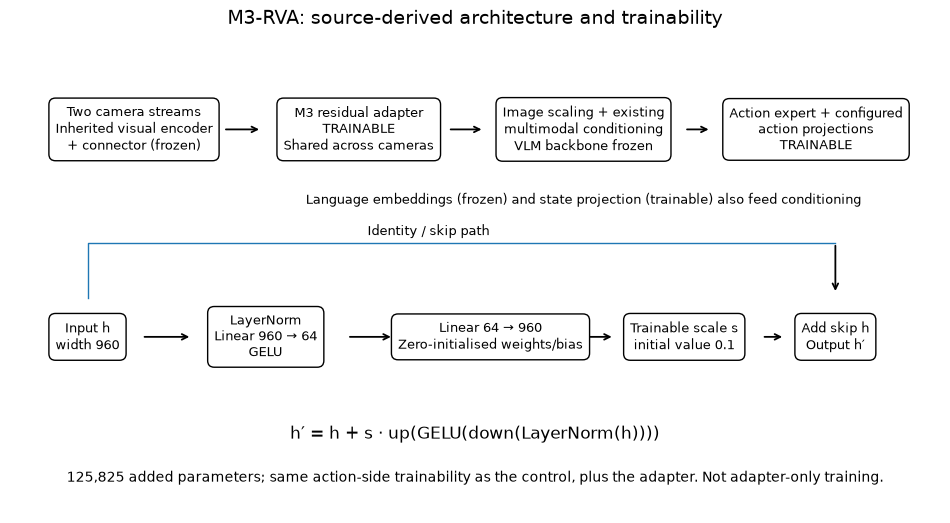

In [4]:
source = source_path("src/m3_rva_training.py").read_text(encoding="utf-8")
core_compute = read_csv(N06 + "final_training_compute_audit.csv")
registry = read_csv(TRAIN + "m3_model_registry.csv")
rank = int(protocol["adapter_rank"])
original_total = int(core_compute["total_parameters"].iloc[0])
added = int(registry["total_parameters"].iloc[0]) - original_total
# LayerNorm affine: 2H; down: HR+R; up: RH+H; residual scale: 1.
width_float = (added - rank - 1) / (2*rank + 3)
check("Adapter parameter accounting", width_float.is_integer())
width = int(width_float)
check("Recorded module matches diagram operations", all(s in source for s in ["nn.LayerNorm(hidden_size)", "nn.Linear(hidden_size, rank)", "nn.GELU()", "nn.Linear(rank, hidden_size)", "connector.register_forward_hook", "nn.init.zeros_(self.up.weight)"]))
check("Recorded source parameters match all seeds", registry.total_parameters.nunique()==1 and registry.trainable_parameters.nunique()==1)
architecture = pd.DataFrame([
    {"component": "Connector token width", "value": width},
    {"component": "Bottleneck width", "value": rank},
    {"component": "Added parameters", "value": added},
    {"component": "Original total parameters", "value": original_total},
    {"component": "M3 total parameters", "value": int(registry.total_parameters.iloc[0])},
    {"component": "M3 trainable parameters", "value": int(registry.trainable_parameters.iloc[0])},
])
save_table(architecture, "03_architecture_accounting.csv", "Calculated from the recorded module and parameter totals; not a fresh model load.")
fig, ax = plt.subplots(figsize=(12, 6.1))
ax.set_xlim(0, 12); ax.set_ylim(0, 6); ax.axis("off")
def box(x, y, text, size=9.5):
    ax.text(x, y, text, ha="center", va="center", fontsize=size,
            bbox={"boxstyle": "round,pad=0.5", "fill": False})
def arrow(a, b, connection="arc3,rad=0"):
    ax.annotate("", xy=b, xytext=a, arrowprops={"arrowstyle": "->", "lw": 1.3, "connectionstyle": connection})
box(1.6, 4.9, "Two camera streams\nInherited visual encoder\n+ connector (frozen)")
box(4.5, 4.9, "M3 residual adapter\nTRAINABLE\nShared across cameras")
box(7.4, 4.9, "Image scaling + existing\nmultimodal conditioning\nVLM backbone frozen")
box(10.4, 4.9, "Action expert + configured\naction projections\nTRAINABLE")
for left, right in [(2.75, 3.25), (5.65, 6.12), (8.7, 9.05)]:
    arrow((left, 4.9), (right, 4.9))
ax.text(7.4, 3.95, "Language embeddings (frozen) and state projection (trainable) also feed conditioning", ha="center", fontsize=9)
box(1, 2.25, f"Input h\nwidth {width}")
box(3.3, 2.25, f"LayerNorm\nLinear {width} → {rank}\nGELU")
box(6.2, 2.25, f"Linear {rank} → {width}\nZero-initialised weights/bias")
box(8.7, 2.25, f"Trainable scale s\ninitial value {protocol['initial_residual_scale']}")
box(10.65, 2.25, "Add skip h\nOutput h′")
for a,b in [((1.7,2.25),(2.35,2.25)),((4.35,2.25),(4.95,2.25)),((7.45,2.25),(7.8,2.25)),((9.7,2.25),(10,2.25))]: arrow(a,b)
ax.plot([1, 1, 10.65], [2.75, 3.45, 3.45], linewidth=1)
arrow((10.65,3.45),(10.65,2.8))
ax.text(5.4,3.55,"Identity / skip path",ha="center",fontsize=9)
ax.text(6,0.95, "h′ = h + s · up(GELU(down(LayerNorm(h))))", ha="center", fontsize=12)
ax.text(6,0.4,f"{added:,} added parameters; same action-side trainability as the control, plus the adapter. Not adapter-only training.",ha="center",fontsize=10)
ax.set_title("M3-RVA: source-derived architecture and trainability", fontsize=14, pad=14)
save_figure(fig, "F01_m3_architecture", "The visual-token adapter is inserted after the inherited connector and before image scaling. Its residual branch initially equals zero. Frozen backbone weights still participate in the differentiable computation; original action-side components remain trainable. Diagram derived from the archived source and manifests.", "Section 4.4 — add to main report", "src/m3_rva_training.py; M3 protocol/registry; N06 compute audit")

## 4. Tuning and training-budget decision record
The six-candidate grid is an early screening experiment, not proof of a globally optimal setting.
The per-seed budget plot makes disagreements between seeds visible; it does not rerun the search.
The original adequacy-check amendment is preserved alongside the retention criteria.

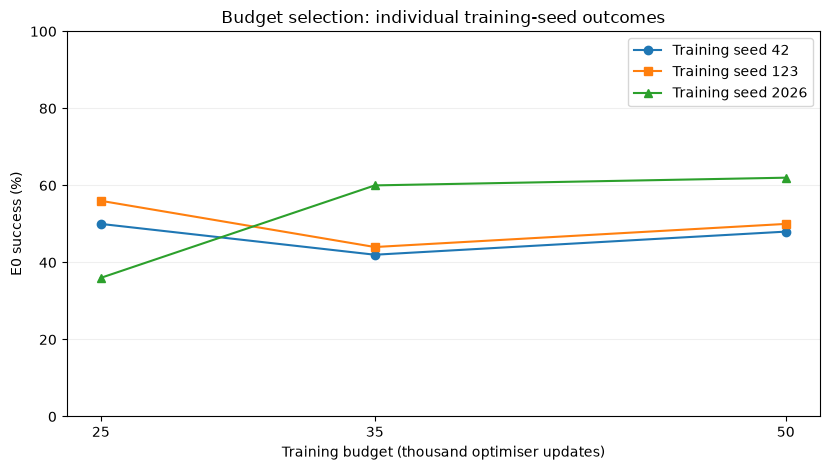

,comparison_steps,delta_vs_25k_pp,bootstrap_95_lower_pp,bootstrap_95_upper_pp,improved_seeds,qualifies_to_replace_25k
0,35000,1.333333,-19.333333,25.333333,1,False
1,50000,6.000000,-13.333333,27.333333,1,False


,Notebook 05 25k seed-42 success,Notebook 05b 25k seed-42 reproduction,Difference (percentage points),Notebook 05 adequacy threshold,Diagnostic status
0,0.633333,0.5,-13.333333,0.533333,VARIABILITY OBSERVED


In [5]:
tuning = read_csv("results/metrics/tuning_final_training/tuning_results.csv", ["learning_rate", "weight_decay", "steps", "validation_loss"])
budget = read_csv(BUDGET + "per_seed_budget_success_summary.csv", ["training_seed", "training_steps", "episodes", "successes", "success_rate"])
criteria = read_csv(BUDGET + "final_budget_replacement_criteria.csv")
repeatability = read_csv(BUDGET + "25k_reproducibility_diagnostic.csv")
check("Six recorded tuning candidates", len(tuning)==6 and tuning.steps.eq(200).all() and np.isfinite(tuning.validation_loss).all())
check("Nine budget checkpoints represented", len(budget)==9 and set(budget.training_seed)==set(SEEDS) and set(budget.training_steps)=={25000,35000,50000})
check("Budget rates match counts", np.allclose(budget.success_rate, budget.successes/budget.episodes))
save_table(tuning[["tuning_id", "learning_rate", "weight_decay", "steps", "batch_size", "seed", "validation_samples", "validation_loss"]].sort_values(["learning_rate", "weight_decay"]), "04_tuning_screen.csv", "Six 200-update candidates; do not describe this as a long-horizon or multi-seed hyperparameter search.")
save_table(criteria, "05_budget_replacement_decisions.csv", "Recorded replacement rules and results; retrospective presentation, not new model selection.")
save_table(repeatability, "06_budget_repeatability_amendment.csv", "Preserves the failed earlier threshold and documented diagnostic status.")
fig, ax = plt.subplots(figsize=(8.4, 4.8))
for seed, marker in zip(SEEDS, ["o", "s", "^"]):
    g = budget[budget.training_seed==seed].sort_values("training_steps")
    ax.plot(g.training_steps/1000, 100*g.success_rate, marker=marker, label=f"Training seed {seed}")
ax.set(xlabel="Training budget (thousand optimiser updates)", ylabel="E0 success (%)", title="Budget selection: individual training-seed outcomes", xticks=[25,35,50], ylim=(0,100))
ax.legend(); ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, "F02_budget_by_seed", "Each point uses 50 E0 episodes. The same seed trajectory supplies its 25k/35k/50k checkpoints. Higher pooled success at 50k did not satisfy the full replacement rule. The extended trajectories retained the schedule reaching its floor at 25k. See the separate repeatability-amendment table; this is not an optimality claim.", "Section 5.2 — replace or supplement the existing mean-only budget figure", BUDGET + "per_seed_budget_success_summary.csv")
display(criteria[["comparison_steps", "delta_vs_25k_pp", "bootstrap_95_lower_pp", "bootstrap_95_upper_pp", "improved_seeds", "qualifies_to_replace_25k"]])
display(repeatability)

## 5. Final validation evidence and recorded training curves
These are saved offline measurements, not new validation runs. The N06 core summary and N09 extension
are identified separately; lower demonstration loss is not necessarily higher closed-loop success.
M3 restoration results are read from the saved training summary, not re-executed.

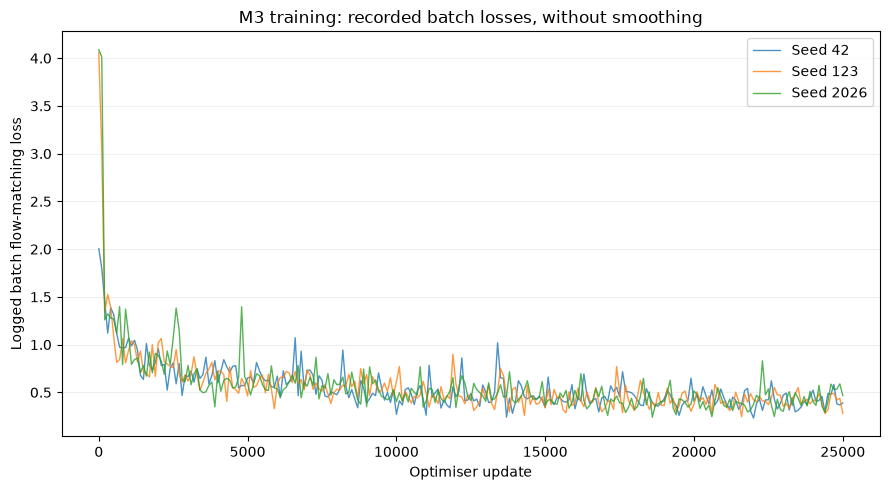

,stage,variant,seed,steps,validation_loss,restoration_status
0,N06 core,M1,42,25000,0.570412,See original N06 evidence; not re-executed here
1,N06 core,M1,123,25000,0.564678,See original N06 evidence; not re-executed here
2,N06 core,M1,2026,25000,0.557629,See original N06 evidence; not re-executed here
3,N06 core,M2-E,42,25000,0.556888,See original N06 evidence; not re-executed here
4,N06 core,M2-L,42,25000,0.589158,See original N06 evidence; not re-executed here
5,N06 core,M2-LE,42,25000,0.581579,See original N06 evidence; not re-executed here
6,N06 core,M2-LE,123,25000,0.557852,See original N06 evidence; not re-executed here
7,N06 core,M2-LE,2026,25000,0.578886,See original N06 evidence; not re-executed here
8,N09 extension,M3-RVA,42,25000,0.586101,PASS
9,N09 extension,M3-RVA,123,25000,0.584373,PASS


In [6]:
core_registry = read_csv("configs/experiments/definitive_final_model_registry_v1.csv")
core_validation = read_csv(N06 + "final_checkpoint_validation_summary.csv")
check("Eight core final checkpoints", len(core_registry)==8 and core_registry.training_steps.eq(25000).all())
validation_rows = []
for row in core_registry.itertuples():
    validation_rows.append({"stage": "N06 core", "variant": row.variant, "seed": int(row.seed), "steps": int(row.training_steps),
                           "validation_loss": float(row.validation_loss), "restoration_status": "See original N06 evidence; not re-executed here", "checkpoint": row.checkpoint})
for row in training["results"]:
    check(f"M3 recorded training/restoration: {row['seed']}", row["steps"]==25000 and row["status"]=="PASS" and row["restoration"]["status"]=="PASS")
    validation_rows.append({"stage": "N09 extension", "variant": row["variant"], "seed": row["seed"], "steps": row["steps"],
                           "validation_loss": row["validation_loss"], "restoration_status": row["restoration"]["status"], "checkpoint": row["checkpoint"]})
validation = pd.DataFrame(validation_rows)
check("Eleven final checkpoint records", len(validation)==11 and np.isfinite(validation.validation_loss).all())
for row in core_validation.itertuples():
    vals = core_registry.loc[core_registry.variant==row.variant, "validation_loss"]
    check(f"N06 aggregate validation agrees: {row.variant}", len(vals)==row.model_count and np.isclose(vals.mean(),row.mean_validation_loss))
save_table(validation, "07_final_checkpoint_validation.csv", "Offline diagnostic losses with source stage and seed. This notebook does not restore or rerun a checkpoint.")

histories = []
fig, ax = plt.subplots(figsize=(9, 5))
for seed in SEEDS:
    rel = f"experiments/m3_rva_extension/v1/m3rva_seed{seed}_25000/train_metrics.csv"
    h = read_csv(rel, ["step", "loss", "learning_rate_used"])
    check(f"Complete finite logged history: {seed}", h.step.is_monotonic_increasing and h.step.is_unique and int(h.step.max())==25000 and np.isfinite(h.loss).all())
    h["seed"] = seed; histories.append(h)
    ax.plot(h.step, h.loss, linewidth=1.0, alpha=0.8, label=f"Seed {seed}")
ax.set(xlabel="Optimiser update", ylabel="Logged batch flow-matching loss", title="M3 training: recorded batch losses, without smoothing")
ax.legend(); ax.grid(axis="y", alpha=0.2); fig.tight_layout()
save_figure(fig, "F03_m3_training_losses", "Unsmoothed logged batch losses from the three completed M3 runs. Logs contain selected updates, not every batch or epoch averages. No repeated validation trajectory is asserted. A lower training objective does not establish better robot success or OOD robustness.", "Section 5 — add one training-behaviour figure", "experiments/m3_rva_extension/v1/m3rva_seed*/train_metrics.csv")
save_table(pd.concat(histories, ignore_index=True), "08_m3_logged_training_history.csv", "Unmodified numerical history with an added seed identifier.")
display(validation[["stage","variant","seed","steps","validation_loss","restoration_status"]])

## 6. Mechanism-oriented view of the original language ablation
This figure uses N07 only, not the fresh N10 comparator. All four instruction levels and all three recorded
seed-42 variants are shown. These operational language categories are not a universal difficulty scale.
The figure supports a limited single-seed ablation interpretation, not a causal representation diagnosis.

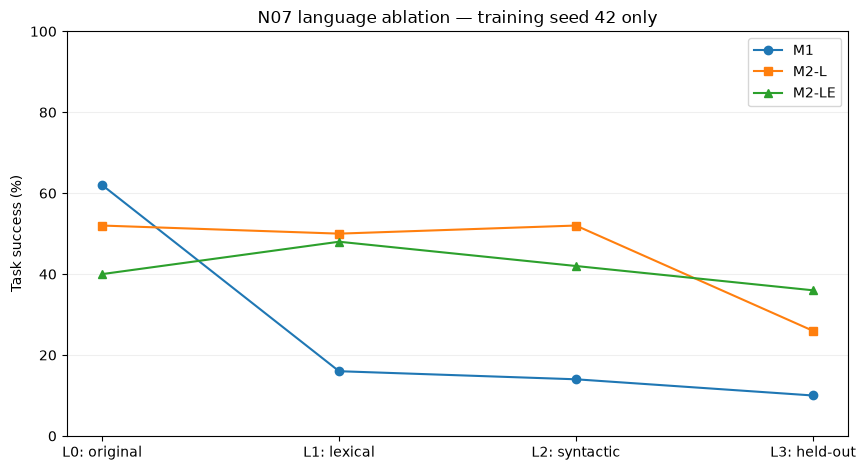

In [7]:
core_episodes = read_csv(CORE + "closed_loop_episode_results.csv", ["variant","model_seed","condition_id","suite_task_id","replica","success"])
core_episodes["success"] = bool_series(core_episodes["success"])
check("N07 completed episode count", len(core_episodes)==2050)
check("Unique N07 episode keys", not core_episodes.duplicated(KEY+["variant"]).any())
core_effects = read_csv(CORE + "primary_hierarchical_paired_effects.csv")
e5 = read_csv("results/metrics/supplementary_double_heldout/closed_loop_episode_results.csv")
e5["success"] = bool_series(e5["success"])
check("N07b completed episode count", len(e5)==300)
check("Unique E5 episode keys", not e5.duplicated(KEY+["variant"]).any())
e5_effect = read_csv("results/metrics/supplementary_double_heldout/e5_hierarchical_paired_effect.csv")
# Confirm published local aggregates against the respective episode tables; never pool the phases.
core_headline = []
for condition in core_effects.condition_id:
    a = core_episodes[(core_episodes.variant=="M1") & (core_episodes.condition_id==condition)].set_index(KEY)
    b = core_episodes[(core_episodes.variant=="M2-LE") & (core_episodes.condition_id==condition)].set_index(KEY)
    z = a[["success"]].join(b[["success"]], lsuffix="_m1", rsuffix="_m2", how="outer")
    check(f"N07 paired schedule: {condition}", len(z)==150 and not z.isna().any().any())
    delta = (z.success_m2.astype(int)-z.success_m1.astype(int)).mean()*100
    check(f"N07 saved effect: {condition}", np.isclose(delta, core_effects.loc[core_effects.condition_id==condition,"observed_delta_pp"].iloc[0]))
    core_headline.append({"condition_id":condition,"valid_pairs":len(z),"M1_pct":z.success_m1.mean()*100,"M2_LE_pct":z.success_m2.mean()*100,"delta_pp":delta})
check("E5 saved difference", np.isclose((e5[e5.variant=="M2-LE"].success.mean()-e5[e5.variant=="M1"].success.mean())*100, e5_effect.observed_delta_pp.iloc[0]))
save_table(pd.DataFrame(core_headline), "09_core_verified_headline.csv", "N07 only; no N10 rates substituted.")
levels = ["E0_ID","E1_L1","E1_L2","E1_L3"]
variants = ["M1","M2-L","M2-LE"]
sub = core_episodes[(core_episodes.model_seed==42) & core_episodes.variant.isin(variants) & core_episodes.condition_id.isin(levels)]
lang = sub.groupby(["variant","condition_id"]).success.agg(["size","sum","mean"]).reset_index()
check("Language ablation balanced", len(lang)==12 and lang["size"].eq(50).all())
lang["success_pct"]=100*lang["mean"]
save_table(lang, "10_language_ablation_seed42.csv", "Single-seed descriptive ablation, not three-seed causal proof.")
fig, ax = plt.subplots(figsize=(8.8, 4.8))
for variant, marker in zip(variants,["o","s","^"]):
    g=lang[lang.variant==variant].set_index("condition_id").reindex(levels)
    ax.plot(range(4),g.success_pct,marker=marker,label=variant)
ax.set(xticks=range(4),xticklabels=["L0: original","L1: lexical","L2: syntactic","L3: held-out"],ylim=(0,100),ylabel="Task success (%)",title="N07 language ablation — training seed 42 only")
ax.legend(); ax.grid(axis="y",alpha=0.2);fig.tight_layout()
save_figure(fig,"F04_language_ablation", "Every point contains 50 episodes. Language-only and combined augmentation improve observed language-shift success relative to M1 in this seed. The standard-condition trade-off remains visible. This does not establish the mechanism across all seeds, and differences between conditions can also reflect their evaluation schedules.", "Section 6.1 — useful mechanism-analysis figure, or appendix if space is tight", CORE+"closed_loop_episode_results.csv")

## 7. Architectural effects, uncertainty and repeatability
The first figure republishes the **saved** N10 intervals; none are recomputed or optimised.
L3 has no confidence interval because the original reporting rule withholds inference for an incomplete condition.
The second figure shows all three training-seed effects, distinguishing repeatability of a difference from
absolute variability of either model. Neither figure measures action consistency.

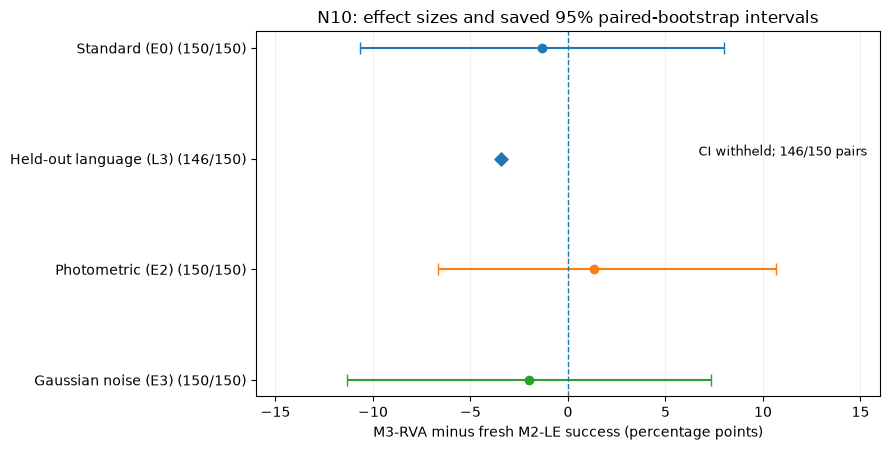

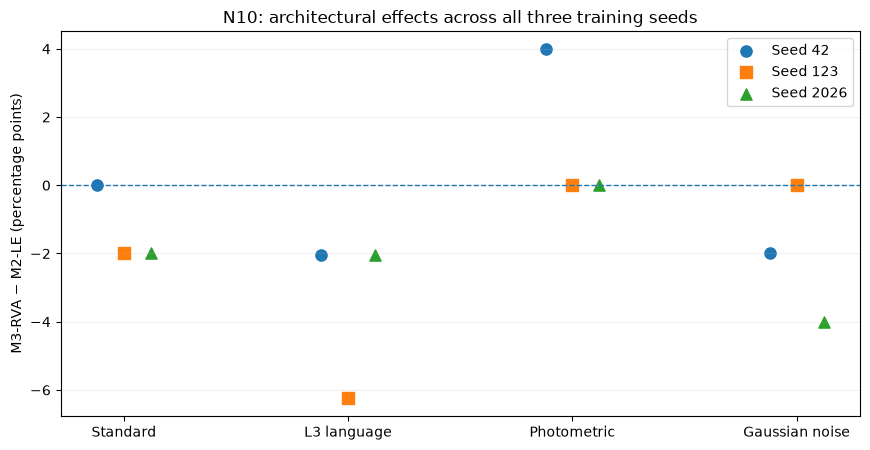

,condition_id,variant,training_seeds,equal_seed_mean_pct,sample_sd_pp,min_pct,max_pct,interpretation
0,E0_ID,M2-LE,3,43.333,3.055,40.000,46.000,Descriptive: only three training seeds; not ac...
1,E0_ID,M3-RVA,3,42.000,4.000,38.000,46.000,Descriptive: only three training seeds; not ac...
2,E1_L3,M2-LE,3,23.299,4.339,18.367,26.531,Descriptive: only three training seeds; not ac...
3,E1_L3,M3-RVA,3,19.855,4.192,16.327,24.490,Descriptive: only three training seeds; not ac...
4,E2_SEEN_PHOTO,M2-LE,3,42.000,9.165,34.000,52.000,Descriptive: only three training seeds; not ac...
5,E2_SEEN_PHOTO,M3-RVA,3,43.333,11.372,34.000,56.000,Descriptive: only three training seeds; not ac...
6,E3_HELDOUT_NOISE,M2-LE,3,50.667,8.083,42.000,58.000,Descriptive: only three training seeds; not ac...
7,E3_HELDOUT_NOISE,M3-RVA,3,48.667,7.024,42.000,56.000,Descriptive: only three training seeds; not ac...


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for y, condition in enumerate(CONDITIONS):
    row = effects[effects.condition_id==condition].iloc[0]
    if pd.notna(row.paired_bootstrap_low_pp):
        ax.errorbar(row.delta_pp,y,xerr=np.array([[row.delta_pp-row.paired_bootstrap_low_pp],[row.paired_bootstrap_high_pp-row.delta_pp]]),fmt="o",capsize=4)
    else:
        ax.scatter([row.delta_pp],[y],marker="D",s=45)
        ax.text(0.98,y,"CI withheld; 146/150 pairs",transform=ax.get_yaxis_transform(),ha="right",va="bottom",fontsize=9)
ax.axvline(0,linestyle="--",linewidth=1)
ax.set(yticks=range(4),yticklabels=[LABELS[x]+f" ({int(effects.set_index('condition_id').loc[x,'complete_pairs'])}/150)" for x in CONDITIONS],xlabel="M3-RVA minus fresh M2-LE success (percentage points)",title="N10: effect sizes and saved 95% paired-bootstrap intervals",xlim=(-16,16))
ax.invert_yaxis();ax.grid(axis="x",alpha=0.2);fig.tight_layout()
save_figure(fig,"F05_m3_effects_and_uncertainty", "Effects use identical complete pairs for both policies. Horizontal bars reproduce N10's saved 95% bootstrap intervals for complete conditions; they do not remove small-seed or clustering limitations. The L3 diamond is a point estimate without inferential interval. Missing-outcome bounds are reported separately, not substituted for a CI.", "Section 6.3 — replace the current mean-only M3 bar chart", N10+"m3_vs_m2le_effects.csv")

fig, ax = plt.subplots(figsize=(8.8,4.6))
for j,(seed,marker) in enumerate(zip(SEEDS,["o","s","^"])):
    g=seed_effects[seed_effects.model_seed==seed].set_index("condition_id").reindex(CONDITIONS)
    ax.scatter(np.arange(4)+(j-1)*0.12,g.delta_pp,marker=marker,s=65,label=f"Seed {seed}")
ax.axhline(0,linestyle="--",linewidth=1)
ax.set(xticks=range(4),xticklabels=["Standard","L3 language","Photometric","Gaussian noise"],ylabel="M3-RVA − M2-LE (percentage points)",title="N10: architectural effects across all three training seeds")
ax.legend();ax.grid(axis="y",alpha=0.2);fig.tight_layout()
save_figure(fig,"F06_m3_seed_effects", "All preselected training seeds are shown. L3 uses 49, 48 and 49 valid pairs; other cells use 50. Seed-specific differences show directional repeatability, not a test of equal model stability. In the supplied results, the photometric gain is confined to seed 42.", "Section 6.3 or appendix — supports the replication discussion", N10+"paired_episode_results.csv")

variability=[]
for condition,g in seed_effects.groupby("condition_id"):
    for variant,col in [("M2-LE","M2_LE_success_pct"),("M3-RVA","M3_RVA_success_pct")]:
        variability.append({"condition_id":condition,"variant":variant,"training_seeds":len(g),"equal_seed_mean_pct":g[col].mean(),"sample_sd_pp":g[col].std(ddof=1),"min_pct":g[col].min(),"max_pct":g[col].max(),"interpretation":"Descriptive: only three training seeds; not action consistency"})
save_table(pd.DataFrame(variability),"11_descriptive_seed_variability.csv","Equal-weight seed means and sample SD; L3 may differ slightly from pooled rates due to unequal denominators.")
task_table=pairs.groupby(["condition_id","suite_task_id"]).agg(valid_pairs=("delta","size"),M2_LE_successes=("success_baseline","sum"),M3_RVA_successes=("success_m3","sum"),delta=("delta","mean")).reset_index()
task_table["planned_pairs"]=15
task_table["pair_coverage_pct"]=100*task_table.valid_pairs/task_table.planned_pairs
task_table["delta_pp"]=100*task_table.pop("delta")
check("Every condition/task shown",len(task_table)==40)
save_table(task_table,"12_exploratory_task_effects_all_tasks.csv","All ten tasks shown per condition. New descriptive report analysis only; no task-specific significance tests or causal failure labels.")
display(pd.DataFrame(variability).round(3))

## 8. Missing-outcome sensitivity: account for uncertainty without inventing scores
Enumerate the possible success counts for the four unscored attempts in the incomplete condition.
These scenarios are hypothetical table rows only. They are not inserted into the episode data, not confidence
intervals, and not evidence that the missing attempts were random. All originally observed baseline outcomes
are retained in the scheduled-sample denominator.

In [9]:
scenarios=[]
for condition in CONDITIONS:
    b=scored[(scored.condition_id==condition)&(scored.variant=="M2-LE")]
    m=scored[(scored.condition_id==condition)&(scored.variant=="M3-RVA")]
    ub=unscored[(unscored.condition_id==condition)&(unscored.variant=="M2-LE")]
    um=unscored[(unscored.condition_id==condition)&(unscored.variant=="M3-RVA")]
    check(f"Scheduled sample denominators: {condition}",len(b)+len(ub)==150 and len(m)+len(um)==150)
    low=100*(int(m.success.sum())-int(b.success.sum())-len(ub))/150
    high=100*(int(m.success.sum())+len(um)-int(b.success.sum()))/150
    recorded=bounds[bounds.condition_id==condition].iloc[0]
    check(f"Saved missing-outcome bounds: {condition}",np.allclose([low,high],[recorded.delta_lower_pp,recorded.delta_upper_pp]))
    if len(um):
        check("This report's scenario table assumes no baseline missing outcomes",len(ub)==0)
        for assumed_successes in range(len(um)+1):
            scenarios.append({"condition_id":condition,"hypothetical_successes_among_unscored":assumed_successes,"unscored_M3_attempts":len(um),"M2_LE_observed_successes":int(b.success.sum()),"M3_observed_successes":int(m.success.sum()),"scheduled_pairs":150,"M2_LE_scheduled_pct":100*b.success.sum()/150,"M3_hypothetical_scheduled_pct":100*(m.success.sum()+assumed_successes)/150,"hypothetical_delta_pp":100*(m.success.sum()+assumed_successes-b.success.sum())/150,"interpretation":"Sensitivity scenario only: NOT imputation or confidence interval"})
save_table(pd.DataFrame(scenarios),"13_missing_outcome_sensitivity.csv","Enumerates possible completions in a separate report table; original missing values remain missing.")
save_table(unscored[["model_seed","variant","condition_id","suite_task_id","replica","status","learned_actions_executed","counts_as_robot_failure"]],"14_technical_exclusions.csv","The four technical exclusions remain unscored and are not retried.")
display(pd.DataFrame(scenarios).round(3))

,condition_id,hypothetical_successes_among_unscored,unscored_M3_attempts,M2_LE_observed_successes,M3_observed_successes,scheduled_pairs,M2_LE_scheduled_pct,M3_hypothetical_scheduled_pct,hypothetical_delta_pp,interpretation
0,E1_L3,0,4,34,29,150,22.667,19.333,-3.333,Sensitivity scenario only: NOT imputation or c...
1,E1_L3,1,4,34,29,150,22.667,20.000,-2.667,Sensitivity scenario only: NOT imputation or c...
2,E1_L3,2,4,34,29,150,22.667,20.667,-2.000,Sensitivity scenario only: NOT imputation or c...
3,E1_L3,3,4,34,29,150,22.667,21.333,-1.333,Sensitivity scenario only: NOT imputation or c...
4,E1_L3,4,4,34,29,150,22.667,22.000,-0.667,Sensitivity scenario only: NOT imputation or c...


## 9. Report integration, evidence integrity and completion
A notebook ending successfully is not a claim of improved M3 performance. This stage exports an evidence map
and writing guidance, then confirms that every source file read by N11 has the same hash as before.
No estimated marks or promised grade are generated.

In [10]:
# Correct report wording: the interval below spans all hypothetical outcomes;
# making all missing M3 attempts successes gives its upper endpoint only.
l3_bound=bounds[bounds.condition_id=="E1_L3"].iloc[0]
review_notes=[
    "The N09 training summary's NOT_EVALUATED field is historical training-stage metadata; N10 supplies robot outcomes.",
    "The N10 summary retains a legacy one-seed limitation string, but its selected seeds and CSVs contain three seeds.",
    "The N10 all_planned_seeds_evaluated flag remains false because the complete scored matrix has four missing outcomes; execution is finished.",
    "The N05b original adequacy threshold did not pass unchanged. Its amendment remains a limitation, not an all-gates-pass claim.",
    "N11 republishes saved CIs and does not revalidate their statistical assumptions; small-seed/clustering limitations remain.",
    "Archive evidence does not contain every raw initial observation or model weight; this is an arithmetic/source audit, not full replay verification.",
]
for name,record in SOURCES.items():
    check(f"Input unchanged: {name}",sha256(ROOT/name)==record["sha256"])
manifest=pd.DataFrame(list(SOURCES.values())).sort_values("path")
manifest.to_csv(OUT/"source_manifest.csv",index=False)
pd.DataFrame(CHECKS).to_csv(OUT/"evidence_audit_checks.csv",index=False)
pd.DataFrame(FIGURE_RECORDS).to_csv(OUT/"figure_catalog.csv",index=False)
pd.DataFrame(TABLE_RECORDS).to_csv(OUT/"table_catalog.csv",index=False)

mapping=pd.DataFrame([
    {"criterion":"Model implementation","evidence":"F01; tables/03_architecture_accounting.csv","report_action":"Explain insertion, identity initialisation and trainability. Do not claim a new foundation model."},
    {"criterion":"Tuning and validation","evidence":"F02; tables/04–07","report_action":"Explain screening → budget comparison → fixed final checkpoints. Retain the adequacy amendment and schedule limitation."},
    {"criterion":"Tuning and validation","evidence":"F03; tables/07–08","report_action":"Interpret recorded batch losses and saved offline validation separately from robot success."},
    {"criterion":"Visualisation and critical analysis","evidence":"F04; tables/09–10","report_action":"Use the single-seed ablation to discuss the language intervention, without causal overclaiming."},
    {"criterion":"Visualisation and critical analysis","evidence":"F05/F06; tables/02,11–14","report_action":"Explain effect uncertainty, replication, all-task descriptive results and missing evidence."},
])
mapping.to_csv(OUT/"rubric_evidence_map.csv",index=False)

sections=[
    "# N11 report integration guide",
    "This package is a read-only post-hoc analysis of the frozen submitted evidence. It does not change the experiments or establish additional training validity.",
    "## Recommended edits (do not insert every figure)",
    "1. Add F01 in Section 4.4: identify what was inherited, what was added, and what trained.",
    "2. Use F02 instead of the mean-only budget figure when explaining why seed consistency matters. Include table 05 and disclose table 06.",
    "3. Add F03 and a compact selection from table 07 in Section 5. Describe the losses as logged training batches; no validation-over-time curve was recorded here.",
    "4. Replace the M3 mean-only bar chart with F05. Use F06 in the appendix or main text to explain replication. Retain the original N07 effect figure.",
    "5. Use F04 only where the language ablation needs visual support; otherwise retain its table. Table 12 can remain in the appendix.",
    "## Draft analytical observations to verify and adapt",
    "The initial grid screens learning rate and weight decay at a short horizon. It does not independently establish the best full-run configuration. Later budget experiments and final checkpoint validation answer different questions.",
    "The budget trajectories disagree by seed. Retaining 25k is a bounded resource decision under the recorded replacement criteria, not evidence that 50k can never help or that every original adequacy check passed.",
    "The original language result improves relative success but leaves a low absolute completion rate. The language-only ablation supports the intervention's relevance within one seed; it does not prove a general internal mechanism.",
    "In the supplied N10 evidence, the photometric benefit appears only in seed 42. The remaining seeds tie, so the average effect is weaker than the initial single-seed observation suggested. No favourable seed is selected or omitted.",
    f"Across all possible outcomes for the four unscored L3 attempts, the scheduled-sample difference ranges from {l3_bound.delta_lower_pp:.2f} to {l3_bound.delta_upper_pp:.2f} percentage points. Assigning success to all four gives the upper endpoint only. These bounds are not CIs or population-level evidence of harm.",
    "## Interpretation safeguards",
    "Keep N07, N07b and N10 results separate. Use fresh N10 M2-LE controls for M3. Differences across conditions can reflect different initial-state schedules, so do not claim that corruption improves performance.",
    "Do not infer failure mechanisms from final screenshots alone. No new attention, trajectory, action-consistency or learning-stability measurement has been performed.",
    "Do not add new p-values, change missing-value rules, select settings or reopen training on the basis of N11. All new task/seed summaries are descriptive report analyses.",
    "Retain the assignment's word allocations. Replace repetition with analysis rather than adding a long technical appendix to the main discussion. Check institutional AI-assistance and attribution requirements.",
    "## Known source limitations", *["- "+x for x in review_notes],
    "## Figure captions and placement",
]
for record in FIGURE_RECORDS:
    sections.extend([f"### {record['figure']}",record["caption"],"Suggested placement: "+record["suggested_placement"],"Source: `"+record["source"]+"`"])
(OUT/"REPORT_INTEGRATION_GUIDE.md").write_text("\n\n".join(sections)+"\n",encoding="utf-8")
completion={"notebook":"11_report_finalization_and_evidence_audit","role":"POST_HOC_REPORT_ANALYSIS_ONLY",
            "status":"COMPLETE","input_files_unchanged":True,"source_count":len(SOURCES),"checks_passed":len(CHECKS),
            "figures_created":len(FIGURE_RECORDS),"tables_created":len(TABLE_RECORDS),
            "training_performed":False,"new_robot_episodes":0,"new_significance_tests":0,"policy_weights_loaded":False,
            "experiment_outputs_modified":False,"n10_accounting":EXPECTED_COUNTS,
            "uncertainty_intervals":"Reused from saved N10 results; no new inferential claims",
            "limitations":review_notes,"environment":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"matplotlib":matplotlib.__version__},
            "output_relative_path":str(OUT.relative_to(ROOT))}
(OUT/"notebook11_summary.json").write_text(json.dumps(completion,indent=2,allow_nan=False)+"\n",encoding="utf-8")
display(mapping)
print("N11 REPORT FINALISATION: COMPLETE")
print("Input files unchanged: True")
print("New training / robot episodes / significance tests: 0 / 0 / 0")
print("Figures:",len(FIGURE_RECORDS),"| Tables:",len(TABLE_RECORDS),"| Audit checks:",len(CHECKS))
print("Output:",OUT)
print("Read REPORT_INTEGRATION_GUIDE.md; retain all original experiment limitations.")

,criterion,evidence,report_action
0,Model implementation,F01; tables/03_architecture_accounting.csv,"Explain insertion, identity initialisation and..."
1,Tuning and validation,F02; tables/04–07,Explain screening → budget comparison → fixed ...
2,Tuning and validation,F03; tables/07–08,Interpret recorded batch losses and saved offl...
3,Visualisation and critical analysis,F04; tables/09–10,Use the single-seed ablation to discuss the la...
4,Visualisation and critical analysis,"F05/F06; tables/02,11–14","Explain effect uncertainty, replication, all-t..."


N11 REPORT FINALISATION: COMPLETE
Input files unchanged: True
New training / robot episodes / significance tests: 0 / 0 / 0
Figures: 6 | Tables: 14 | Audit checks: 119
Output: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/report_finalization/20261025T124022_898151Z
Read REPORT_INTEGRATION_GUIDE.md; retain all original experiment limitations.
